In [1]:
from rdkit import Chem
import pickle
import os
import json
import numpy as np
import xgboost
import sys
sys.path.append('molecule-web-app/backend')
from ml_helper import make_fingerprint # pyright: ignore[reportMissingImports]
from matplotlib import pyplot as plt
from cycler import cycler

from matplotlib.colors import ListedColormap
import numpy as np


In [2]:
# Data analysis



arrow_types = {
    0: "atom to atom",
    1: "atom to bond",
    2: "bond to atom",
    3: "bond to bond",
    4: "atom to H+",
    5: "bond to H+",
    6: "H- to atom",
    7: "H- to bond",
    8: '-H+ to bond',
    9: '-H+ to atom',
    10: 'elimination to bond'
}


training_dir = "training_sets/20251215"

with open('bitvector_origins.txt', 'w') as origin_file:
    pass #

# Get list of subdirectories and sort them numerically
subdirs = [d for d in os.listdir(training_dir) if os.path.isdir(os.path.join(training_dir, d))]
subdirs = sorted(subdirs, key=lambda x: int(x))  # Sort by integer folder name

bitvectors = []
outcomes = []
contributors = {}
count_dirs = 0
count_arrows = 0

for subdir in subdirs:
    count_dirs += 1
    folder_path = os.path.join(training_dir, subdir)
    json_path = os.path.join(folder_path, 'data.json')
    pkl_path = os.path.join(folder_path, 'sm.pkl')
    with open(pkl_path, "rb") as f:
        try:
            sm = pickle.load(f)
        except Exception as e:
                    print(f"Error processing {pkl_path}: {e}")
    with open(json_path, 'r') as file:
        data = json.load(file)
    choices = data['choices']
    contributor = data.get('contributor')
    if contributor in contributors:
        if contributor == '':
             contributors[None] += 1
        else:
            contributors[contributor] += 1
    else:
        if contributor == '':
             contributors[None] = 1
        else:
            contributors[contributor] = 1
    for id, info in choices.items():
        # bitvector for the mechanism
        if info['probable'] is None:
            continue
        try:
            sum_finger_print = make_fingerprint(sm, info['mechanism'])
        except:
             print(f"Error processing {training_dir}/{subdir} mechanism {info['mechanism']}")
        bitvectors.append(sum_finger_print)
        
        count_arrows += 1
        outcomes.append(info['probable'])
        # Track the origin of each bitvector
        with open("bitvector_origins.txt", "a") as origin_file:
            origin_file.write(f"{len(bitvectors)-1},{training_dir}/{subdir},{id}\n")


print(f"total directories: {count_dirs}, total arrows: {count_arrows}")


total directories: 298, total arrows: 7003


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, recall_score, precision_score, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay, auc

In [10]:
X_train, X_test, y_train, y_test = train_test_split(bitvectors, outcomes, test_size=0.25)


In [13]:
import pickle
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_val_score
from hyperopt import fmin, tpe, hp, Trials, STATUS_OK, space_eval
from xgboost import XGBClassifier

# Cell 0: hyperopt tuning for XGBoost (expects X_train/y_train in notebook or X_train.pkl & y_train.pkl)

# load data (either from variables or pickles)

X = X_train
y = y_train

# search space
space = {
    "n_estimators": hp.quniform("n_estimators", 50, 1000, 1),
    "max_depth": hp.quniform("max_depth", 3, 12, 1),
    "learning_rate": hp.loguniform("learning_rate", np.log(0.01), np.log(0.3)),
    "subsample": hp.uniform("subsample", 0.5, 1.0),
    "colsample_bytree": hp.uniform("colsample_bytree", 0.3, 1.0)
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

def objective(params):
    params = params.copy()
    params["n_estimators"] = int(params["n_estimators"])
    params["max_depth"] = int(params["max_depth"])
    model = XGBClassifier(
        n_jobs=-1,
        use_label_encoder=False,
        eval_metric="logloss",
        verbosity=0,
        random_state=42,
        scale_pos_weight=7,
        min_child_weight=1,
        reg_alpha=3.690459014854286e-06,
        reg_lambda=6.02486755545729e-07,
        **params
    )
    scores = cross_val_score(model, X, y, cv=cv, scoring="average_precision", n_jobs=-1)
    return {"loss": 1.0 - scores.mean(), "status": STATUS_OK}

trials = Trials()
best = fmin(fn=objective, space=space, algo=tpe.suggest, max_evals=60, trials=trials)
best_params = space_eval(space, best)
best_params["n_estimators"] = int(best_params["n_estimators"])
best_params["max_depth"] = int(best_params["max_depth"])

# train final model on full data
best_model = XGBClassifier(
    use_label_encoder=False,
    eval_metric="logloss",
    verbosity=0,
    n_jobs=-1,
    random_state=42,
    **best_params
)
best_model.fit(X, y)

# save model and print best params
#pickle.dump(best_model, open("xgb_best.pkl", "wb"))
print("best_params:", best_params)

100%|██████████| 60/60 [01:13<00:00,  1.23s/trial, best loss: 0.1328895822914825] 
best_params: {'colsample_bytree': 0.3044382483479869, 'learning_rate': 0.015984011128163115, 'max_depth': 9, 'n_estimators': 994, 'subsample': 0.6341307393222927}


In [14]:
best_model.save_model('models/v53/xg_model.json')

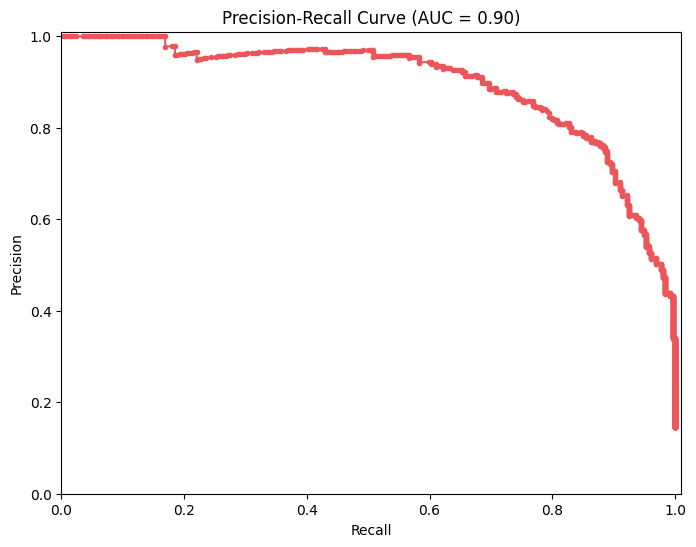

In [15]:
# Make predictions on the test set
y_pred = best_model.predict_proba(X_test)[:, 1]
 
# Calculate precision, recall, and thresholds
precision, recall, thresholds = precision_recall_curve(y_test, y_pred)
 
# Calculate the area under the PR curve
auc_score = auc(recall, precision)
 
# Plot the Precision-Recall curve
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, marker='.', label='PR Curve', color='#ea565aff')
plt.xlim(0, 1.01)
plt.ylim(0, 1.01)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall Curve (AUC = {auc_score:.2f})')
plt.show()